<a href="https://colab.research.google.com/github/gtserve/airbnb-analysis/blob/main/notebooks/02_nlp_sentiment_and_semantic_similarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Athens Airbnb: Review Sentiment Analysis

Apply a pretrained RoBERTa sentiment model to guest reviews, explore label distributions over time, and compare classical classifiers using TF-IDF and averaged Word2Vec embeddings.

**Scope:** Sample 1,000 reviews from each snapshot-year collection and split each labelled sample into 800 training and 200 test examples. Snapshot collections contain historical reviews, so the snapshot year is distinct from the year a review was written.

**Reading guide:** Part 1 prepares reviews and generates sentiment labels. Part 2 compares SVM, Random Forest and KNN across two text representations. Part 3 records an extension that has not been implemented. Saved outputs are included; execution currently requires the original datasets and Google Drive paths.

## Environment and Shared Utilities

In [ ]:
# Mount Google Drive.
from google.colab import drive

drive.mount('/content/gdrive/', force_remount=True)

Mounted at /content/gdrive/


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from transformers import pipeline
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

PROJECT_DIR = '/content/gdrive/MyDrive/University/Data Mining/Project 2'
DATA_DIR = '/content/gdrive/MyDrive/University/Data Mining/data'

SENTIMENT_DICT = {
    'negative': 0,
    'neutral':  1,
    'positive': 2,
}

PATTERNS = [
    (re.compile("\("), " "),
    (re.compile("\)"), " "),
    (re.compile("@[A-Za-z0-9_]+"), ""),       # Remove mentions (whole)
    (re.compile(r"http\S+"), ""),             # Remove links.
    (re.compile(r"www.\S+"), ""),
    (re.compile(r"\b[0-9]+\b\s*"), ""),       # Remove numeric words.
    (re.compile("#"), ""),                    # Remove hashtags (only '#')
    (re.compile("[^a-z0-9 \n\t]"), ""),       # Remove all non-alphanumeric, non-whitespace characters.
]

def get_word_embeddings(texts, model):
    embeddings = []
    for text in texts:
        words = text.split()
        word_vectors = [model.wv[word] for word in words if word in model.wv]
        if word_vectors:
            embeddings.append(np.mean(word_vectors, axis=0))
        else:
            embeddings.append(np.zeros(model.vector_size))
    return pd.DataFrame(embeddings)

def clean_text(text: str, patterns: list):
    if not text:
        return text

    text = str(text)

    # Turn all upper alphabetic characters to lower.
    text = text.lower()

    # Remove every pattern given by regex list.
    for p, s in patterns:
        text = p.sub(s, text)

    # Tokenize text as words.
    words = word_tokenize(text)

    # Remove stop-words and split hyphens (word-word, word/word).
    stop_words = set(stopwords.words('english'))
    temp = []
    for word in words:
        if word in stop_words:
            continue

        if "/" in word:
            temp.extend(word.split("/"))
        elif "-" in word:
            temp.extend(word.split("-"))
        else:
            temp.append(word)
    words = temp

    # Join words in text.
    text = " ".join(w for w in words)

    if not text:
        return ""

    return text


nltk.download('wordnet')
nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

# 1. Review Sentiment Over Time

## 1.0 Review Preparation

In [ ]:
# Read 2019 reviews.
with open(f"{DATA_DIR}/2019/april/reviews.csv", "r") as file:
    reviews_19a = pd.read_csv(file, low_memory=False)
with open(f"{DATA_DIR}/2019/february/reviews.csv", "r") as file:
    reviews_19f = pd.read_csv(file, low_memory=False)
with open(f"{DATA_DIR}/2019/march/reviews.csv", "r") as file:
    reviews_19m = pd.read_csv(file, low_memory=False)

# Concatenate 2019 reviews and drop unecessary columns.
reviews_19 = pd.concat([reviews_19f, reviews_19a, reviews_19m], ignore_index=True)
reviews_19.drop(['listing_id', 'reviewer_id', 'reviewer_name'], axis='columns', inplace=True)
print(f"2019: {reviews_19.shape[0]:,d} reviews")

# Read 2023 reviews.
with open(f"{DATA_DIR}/2023/june/reviews.csv", "r") as file:
    reviews_23j = pd.read_csv(file, low_memory=False)
with open(f"{DATA_DIR}/2023/march/reviews.csv", "r") as file:
    reviews_23m = pd.read_csv(file, low_memory=False)
with open(f"{DATA_DIR}/2023/september/reviews.csv", "r") as file:
    reviews_23s = pd.read_csv(file, low_memory=False)

# Concatenate 2023 reviews and drop unecessary columns.
reviews_23 = pd.concat([reviews_23m, reviews_23j, reviews_23s], ignore_index=True)
reviews_23.drop(['listing_id', 'reviewer_id', 'reviewer_name'], axis='columns', inplace=True)
print(f"2023: {reviews_23.shape[0]:,d} reviews")


2019: 843,877 reviews
2023: 1,698,437 reviews


In [ ]:
r19_sample = reviews_19.sample(1500, ignore_index=True)
r23_sample = reviews_23.sample(1500, ignore_index=True)

In [ ]:
# Transform 2019 reviews.
r19_transformed = r19_sample.drop_duplicates(subset=['id'], keep='first')
r19_transformed.loc[:, 'comments'] = r19_transformed['comments'].apply(clean_text, args=(PATTERNS,))
r19_transformed.loc[:, 'comments'] = r19_transformed['comments'].apply(lambda x: None if len(x) < 3 else x)
r19_transformed = r19_transformed.dropna(subset=['comments'])
r19_transformed = r19_transformed.rename(columns={'comments': 'text'})
print(f"2019: {r19_transformed.shape[0]:,d} reviews")

# Transform 2023 reviews.
r23_transformed = r23_sample.drop_duplicates(subset=['id'], keep='first')
r23_transformed.loc[:, 'comments'] = r23_transformed['comments'].apply(clean_text, args=(PATTERNS,))
r23_transformed.loc[:, 'comments'] = r23_transformed['comments'].apply(lambda x: None if len(x) < 3 else x)
r23_transformed = r23_transformed.dropna(subset=['comments'])
r23_transformed = r23_transformed.rename(columns={'comments': 'text'})
print(f"2023: {r23_transformed.shape[0]:,d} reviews")


2019: 1,399 reviews
2023: 1,358 reviews


In [ ]:
# Narrow down reviews to a 1000.
r19_transformed = r19_transformed.sample(1000, ignore_index=True)
r23_transformed = r23_transformed.sample(1000, ignore_index=True)
print(r19_transformed)

            id        date                                               text
0    112474879  2016-11-06  maria great host always kind us even never met...
1      7110575  2013-09-06  husband pleasant experience charming agelikis ...
2    347866290  2018-11-12  elenis place fantastic looks pictures stylish ...
3    260568606  2018-05-04  cozy apartment clean kitchen equipped really g...
4    255656682  2018-04-21  absolutely amazing host went beyond us whether...
..         ...         ...                                                ...
995  366681387  2019-01-03  nice place nice neighborhood little trouble co...
996  265485881  2018-05-17  steven great communicate prior stay quick resp...
997  282026865  2018-06-26  great space great location amazing view roofto...
998  245660165  2018-03-23  highly recommend staying nadinas place place w...
999  247656291  2018-03-29  great place stay athens night good value money...

[1000 rows x 3 columns]


In [ ]:
# Save transformed reviews.
r19_transformed.to_csv(f'{PROJECT_DIR}/data_p2/reviews_19.csv', index=False)
r23_transformed.to_csv(f'{PROJECT_DIR}/data_p2/reviews_23.csv', index=False)

In [ ]:
# Read stored and clean reviews.
with open(f"{PROJECT_DIR}/data_p2/reviews_19.csv", "r") as file:
    reviews_19 = pd.read_csv(file, low_memory=False)
with open(f"{PROJECT_DIR}/data_p2/reviews_23.csv", "r") as file:
    reviews_23 = pd.read_csv(file, low_memory=False)

## 1.1 Sentiment Annotation with RoBERTa

Use `j-hartmann/sentiment-roberta-large-english-3-classes` to assign positive, neutral or negative labels. These are model-generated annotations rather than human-verified sentiment labels.

In [ ]:
classifier = pipeline(
    "text-classification",
    model="j-hartmann/sentiment-roberta-large-english-3-classes"
)

Some weights of the model checkpoint at j-hartmann/sentiment-roberta-large-english-3-classes were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
# Classify 2019 reviews.
results_19 = classifier(list(reviews_19['text']))

In [ ]:
# Classify 2023 reviews.
results_23 = classifier(list(reviews_23['text']))

In [ ]:
reviews_19.loc[:, 'label'] = [r['label'] for r in results_19]
reviews_19.loc[:, 'score'] = [r['score'] for r in results_19]

reviews_23.loc[:, 'label'] = [r['label'] for r in results_23]
reviews_23.loc[:, 'score'] = [r['score'] for r in results_23]

Text(0, 0.5, '')

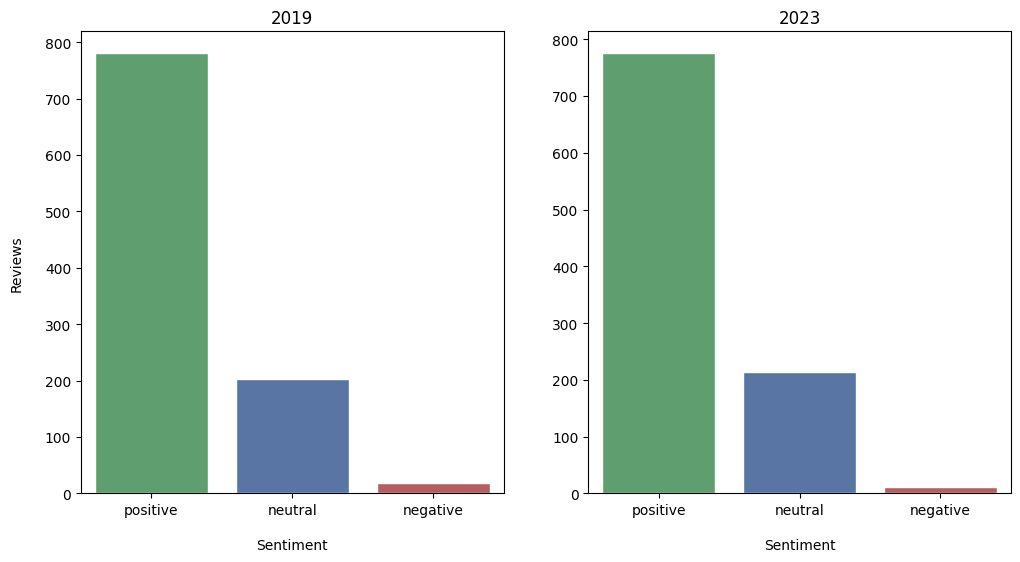

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharex=True)
sns.set_theme()

sns.countplot(ax=ax[0], data=reviews_19, x='label', hue='label', palette=['g', 'b', 'r'])
ax[0].set_title('2019')
ax[0].set_xlabel('Sentiment', labelpad=15)
ax[0].set_ylabel('Reviews', labelpad=15)

sns.countplot(ax=ax[1], data=reviews_23, x='label', hue='label', palette=['g', 'b', 'r'])
ax[1].set_title('2023')
ax[1].set_xlabel('Sentiment', labelpad=15)
ax[1].set_ylabel('')

In [ ]:
reviews_19['year'] = reviews_19['date'].apply(lambda x: x.split('-')[0])
reviews_23['year'] = reviews_23['date'].apply(lambda x: x.split('-')[0])

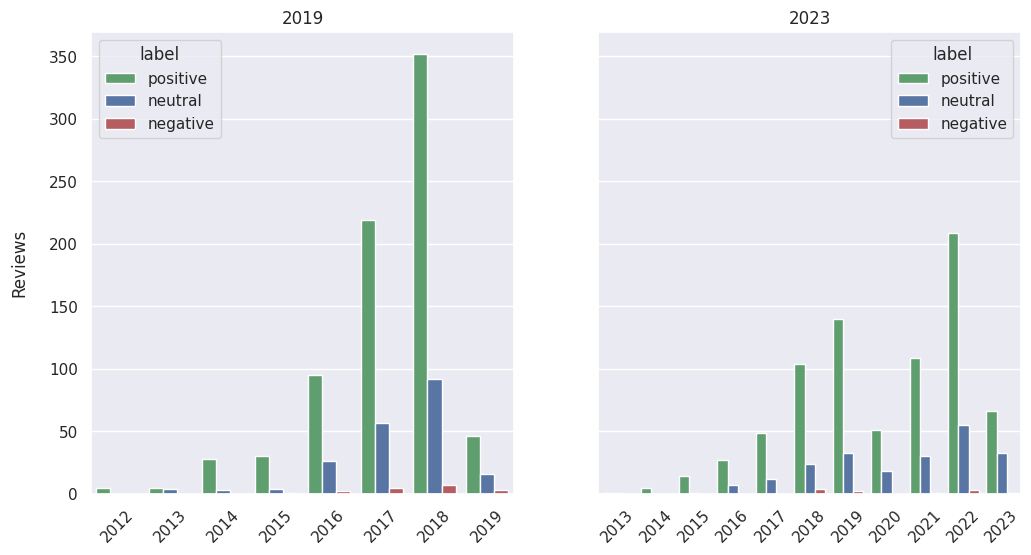

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
sns.set_theme()

reviews_19.groupby('year')

sns.countplot(
    ax=ax[0],
    data=reviews_19,
    x='year',
    hue='label',
    palette=['g', 'b', 'r'],
    order=reviews_19['year'].sort_values()
)
ax[0].set_title('2019')
ax[0].set_xlabel('', labelpad=15)
ax[0].set_ylabel('Reviews', labelpad=15)
ax[0].tick_params(axis='x', rotation=45)

sns.countplot(
    ax=ax[1],
    data=reviews_23,
    x='year',
    hue='label',
    palette=['g', 'b', 'r'],
    order=reviews_23['year'].sort_values()
)

ax[1].set_title('2023')
ax[1].set_xlabel('', labelpad=15)
ax[1].set_ylabel('')
ax[1].tick_params(axis='x', rotation=45)

# 2. Sentiment Classification

Compare SVM, Random Forest and KNN using TF-IDF features and averaged 100-dimensional Word2Vec embeddings. The code reports 10-fold cross-validation accuracy and held-out classification reports.

**Interpretation:** Scores measure agreement with the RoBERTa-generated labels. The saved experiments have class imbalance and fit text representations before cross-validation; evaluation improvements and a clean rerun are pending.

## 2.0 Training and Test Data Preparation

In [ ]:
from sklearn.model_selection import train_test_split

# Split reviews to train and test sets.
train_19, test_19 = train_test_split(reviews_19, test_size=0.20, random_state=42)
train_23, test_23 = train_test_split(reviews_23, test_size=0.20, random_state=42)

# Save data sets with necessary columns.
train_19[['id', 'text', 'label']].to_csv(f'{PROJECT_DIR}/data_p2/train_19.csv', index=False)
test_19[['id', 'text', 'label']].to_csv(f'{PROJECT_DIR}/data_p2/test_19.csv', index=False)

train_23[['id', 'text', 'label']].to_csv(f'{PROJECT_DIR}/data_p2/train_23.csv', index=False)
test_23[['id', 'text', 'label']].to_csv(f'{PROJECT_DIR}/data_p2/test_23.csv', index=False)

## 2.1 Reviews from the 2019 Snapshots

In [ ]:
# Read stored data sets.
with open(f'{PROJECT_DIR}/data_p2/train_19.csv', 'r') as csv_file:
    train_19 = pd.read_csv(csv_file, low_memory=False)
with open(f'{PROJECT_DIR}/data_p2/test_19.csv', 'r') as csv_file:
    test_19 = pd.read_csv(csv_file, low_memory=False)

### 2.1.1 Vectorization

In [ ]:
tf_idf_vect = TfidfVectorizer(max_df=1.0, min_df=20, max_features=None, stop_words='english')

X_train_tfidf = pd.DataFrame(tf_idf_vect.fit_transform(train_19['text']).toarray())
X_test_tfidf = pd.DataFrame(tf_idf_vect.transform(test_19['text']).toarray())

model = Word2Vec(
    sentences=train_19['text'].apply(lambda x: x.split()),
    vector_size=100,
    window=5,
    min_count=1,
    workers=4
)

X_train_embeddings = get_word_embeddings(train_19['text'], model)
X_test_embeddings = get_word_embeddings(test_19['text'], model)

Y_train = train_19['label'].apply(lambda x: SENTIMENT_DICT[x])
Y_test = test_19['label'].apply(lambda x: SENTIMENT_DICT[x])

print(f'X_train_tfidf: {X_train_tfidf.shape}')
print(f'X_test_tfidf: {X_test_tfidf.shape}')
print('\n')
print(f'X_train_embeddings: {X_train_embeddings.shape}')
print(f'X_test_embeddings: {X_test_embeddings.shape}')
print('\n')
print(f'Y_train: {Y_train.shape}')
print(f'Y_test: {Y_test.shape}')


X_train_tfidf: (800, 164)
X_test_tfidf: (200, 164)


X_train_embeddings: (800, 100)
X_test_embeddings: (200, 100)


Y_train: (800,)
Y_test: (200,)


### 2.1.2 Classifier Evaluation

In [ ]:
classifiers = {
    'SVM': SVC(),
    'RFC': RandomForestClassifier(),
    'KNN': KNeighborsClassifier()
}

for name, clf in classifiers.items():
    print('-' * 80)
    print(f' {name} - TF_IDF')
    print('-' * 80)
    scores = cross_val_score(clf, X_train_tfidf, np.array(Y_train), cv=10, scoring='accuracy')
    clf.fit(X_train_tfidf, Y_train)
    Y_pred = clf.predict(X_test_tfidf)
    print(classification_report(Y_test, Y_pred, zero_division=0, digits=3))
    print(f'Accuracy: {round(scores.mean(), 3)}')
    print('\n')

    print('-' * 80)
    print(f' {name} - Word Embeddings')
    print('-' * 80)
    scores = cross_val_score(clf, X_train_embeddings, np.array(Y_train), cv=10, scoring='accuracy')

    clf.fit(X_train_embeddings, Y_train)
    Y_pred = clf.predict(X_test_embeddings)
    print(classification_report(Y_test, Y_pred, zero_division=0, digits=3))
    print(f'Accuracy: {round(scores.mean(), 3)}')
    print('\n\n')


--------------------------------------------------------------------------------
 SVM - TF_IDF
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.906     0.644     0.753        45
           2      0.893     0.980     0.935       153

    accuracy                          0.895       200
   macro avg      0.600     0.542     0.563       200
weighted avg      0.887     0.895     0.884       200

Accuracy: 0.894


--------------------------------------------------------------------------------
 SVM - Word Embeddings
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.909     0.222     0.357        45
           2      0.804     0.993     0.889       153

    accuracy                          0.810       200
   macro avg      0.571     0.405     0.415       200
weighted avg      0.820     0.810     0.760       200

Accuracy: 0.81



--------------------------------------------------------------------------------
 RFC - TF_IDF
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


... (2 outputs left out)

              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.900     0.600     0.720        45
           2      0.882     0.980     0.929       153

    accuracy                          0.885       200
   macro avg      0.594     0.527     0.550       200
weighted avg      0.877     0.885     0.873       200

Accuracy: 0.883



--------------------------------------------------------------------------------
 KNN - TF_IDF
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.295     0.956     0.450        45
           2      0.944     0.333     0.493       153

    accuracy                          0.470       200
   macro avg      0.413     0.430     0.314       200
weighted avg      0.789     0.470     0.478       200

Accuracy: 0.418


--------------------------------------------------------------------------------
 KNN - Word Embeddings
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.806     0.644     0.716        45
           2      0.890     0.954     0.921       153

    accuracy                          0.875       200
   macro avg      0.565     0.533     0.546       200
weighted avg      0.862     0.875     0.866       200

Accuracy: 0.87





/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


## 2.2 Reviews from the 2023 Snapshots

In [ ]:
# Read stored data sets.
with open(f'{PROJECT_DIR}/data_p2/train_23.csv', 'r') as csv_file:
    train_23 = pd.read_csv(csv_file, low_memory=False)
with open(f'{PROJECT_DIR}/data_p2/test_23.csv', 'r') as csv_file:
    test_23 = pd.read_csv(csv_file, low_memory=False)

### 2.2.1 Vectorization

In [ ]:
tf_idf_vect = TfidfVectorizer(max_df=1.0, min_df=20, max_features=None, stop_words='english')

X_train_tfidf = pd.DataFrame(tf_idf_vect.fit_transform(train_23['text']).toarray())
X_test_tfidf = pd.DataFrame(tf_idf_vect.transform(test_23['text']).toarray())

model = Word2Vec(
    sentences=train_23['text'].apply(lambda x: x.split()),
    vector_size=100,
    window=5,
    min_count=1,
    workers=4
)

X_train_embeddings = get_word_embeddings(train_23['text'], model)
X_test_embeddings = get_word_embeddings(test_23['text'], model)

Y_train = train_23['label'].apply(lambda x: SENTIMENT_DICT[x])
Y_test = test_23['label'].apply(lambda x: SENTIMENT_DICT[x])

print(f'X_train_tfidf: {X_train_tfidf.shape}')
print(f'X_test_tfidf: {X_test_tfidf.shape}')
print('\n')
print(f'X_train_embeddings: {X_train_embeddings.shape}')
print(f'X_test_embeddings: {X_test_embeddings.shape}')
print('\n')
print(f'Y_train: {Y_train.shape}')
print(f'Y_test: {Y_test.shape}')

X_train_tfidf: (800, 134)
X_test_tfidf: (200, 134)


X_train_embeddings: (800, 100)
X_test_embeddings: (200, 100)


Y_train: (800,)
Y_test: (200,)


### 2.2.2 Classifier Evaluation

In [ ]:
classifiers = {
    'SVM': SVC(),
    'RFC': RandomForestClassifier(),
    'KNN': KNeighborsClassifier()
}

for name, clf in classifiers.items():
    print('-' * 80)
    print(f' {name} - TF_IDF')
    print('-' * 80)
    scores = cross_val_score(clf, X_train_tfidf, np.array(Y_train), cv=10, scoring='accuracy')
    clf.fit(X_train_tfidf, Y_train)
    Y_pred = clf.predict(X_test_tfidf)
    print(classification_report(Y_test, Y_pred, zero_division=0, digits=3))
    print(f'Accuracy: {round(scores.mean(), 3)}')
    print('\n')

    print('-' * 80)
    print(f' {name} - Word Embeddings')
    print('-' * 80)
    scores = cross_val_score(clf, X_train_embeddings, np.array(Y_train), cv=10, scoring='accuracy')

    clf.fit(X_train_embeddings, Y_train)
    Y_pred = clf.predict(X_test_embeddings)
    print(classification_report(Y_test, Y_pred, zero_division=0, digits=3))
    print(f'Accuracy: {round(scores.mean(), 3)}')
    print('\n\n')


--------------------------------------------------------------------------------
 SVM - TF_IDF
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.906     0.644     0.753        45
           2      0.893     0.980     0.935       153

    accuracy                          0.895       200
   macro avg      0.600     0.542     0.563       200
weighted avg      0.887     0.895     0.884       200

Accuracy: 0.894


--------------------------------------------------------------------------------
 SVM - Word Embeddings
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.900     0.200     0.327        45
           2      0.800     0.993     0.886       153

    accuracy                          0.805       200
   macro avg      0.567     0.398     0.405       200
weighted avg      0.815     0.805     0.752       200

Accuracy: 0.81



--------------------------------------------------------------------------------
 RFC - TF_IDF
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.854     0.778     0.814        45
           2      0.925     0.961     0.942       153

    accuracy                          0.910       200
   macro avg      0.593     0.580     0.585       200
weighted avg      0.899     0.910     0.904       200

Accuracy: 0.9


--------------------------------------------------------------------------------
 RFC - Word Embeddings
--------------------------------------------------------------------------------


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.903     0.622     0.737        45
           2      0.888     0.980     0.932       153

    accuracy                          0.890       200
   macro avg      0.597     0.534     0.556       200
weighted avg      0.882     0.890     0.879       200

Accuracy: 0.886



--------------------------------------------------------------------------------
 KNN - TF_IDF
--------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.295     0.956     0.450        45
           2      0.944     0.333     0.493       153

    accuracy                          0.470       200
   macro avg      0.413     0.430     0.314       200
weighted avg      0.789     0.470     0.478       200

Accuracy: 0.418


-------------------------

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:700: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


              precision    recall  f1-score   support

           0      0.000     0.000     0.000         2
           1      0.867     0.578     0.693        45
           2      0.876     0.974     0.923       153

    accuracy                          0.875       200
   macro avg      0.581     0.517     0.539       200
weighted avg      0.865     0.875     0.862       200

Accuracy: 0.874





# 3. Semantic Neighbourhood Similarity (Not Implemented)

Planned extension: compare word similarity using embedding neighbourhoods and investigate the effect of neighbourhood size. No implementation or results are included in this notebook.